In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/guisahanes/traffic-violation-detection-dataset/data.yaml
/kaggle/input/datasets/guisahanes/traffic-violation-detection-dataset/images/train/bdd_002b485a-3f6603f2_crop0_crop0.jpg
/kaggle/input/datasets/guisahanes/traffic-violation-detection-dataset/images/train/bdd_0090c713-683fc99a_crop1_crop0.jpg
/kaggle/input/datasets/guisahanes/traffic-violation-detection-dataset/images/train/bdd_0090c713-683fc99a_crop2_crop0.jpg
/kaggle/input/datasets/guisahanes/traffic-violation-detection-dataset/images/train/bdd_00c4c672-26d36ad8_crop0_crop0.jpg
/kaggle/input/datasets/guisahanes/traffic-violation-detection-dataset/images/train/bdd_01460ec4-a1d65b66_crop0_crop0.jpg
/kaggle/input/datasets/guisahanes/traffic-violation-detection-dataset/images/train/bdd_01ebc74a-5c69af71_crop0_crop0.jpg
/kaggle/input/datasets/guisahanes/traffic-violation-detection-dataset/images/train/bdd_01ebc74a-5c69af71_crop1_crop0.jpg
/kaggle/input/datasets/guisahanes/traffic-violation-detection-dataset/ima

In [2]:
import torch

print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Device:", torch.cuda.get_device_name(0))

CUDA available: True
Device: Tesla T4


In [3]:
!pip install -q ultralytics
from ultralytics import YOLO

print("Ultralytics ready!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics ready!


In [4]:
import os
import yaml

dataset_dir = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "data.yaml" in files:
        dataset_dir = root
        break

print("Exact dataset_dir:", dataset_dir)
print("Train exists:", os.path.exists(os.path.join(dataset_dir, "images/train")))
print("Val exists:", os.path.exists(os.path.join(dataset_dir, "images/val")))

orig_yaml_path = os.path.join(dataset_dir, "data.yaml")
with open(orig_yaml_path, "r") as f:
    data_cfg = yaml.safe_load(f)

data_cfg["path"] = dataset_dir
data_cfg["train"] = "images/train"
data_cfg["val"] = "images/val"

fixed_yaml_path = "/kaggle/working/fixed_data.yaml"
with open(fixed_yaml_path, "w") as f:
    yaml.safe_dump(data_cfg, f, sort_keys=False)

print("Saved fixed_data.yaml successfully! Classes:", data_cfg["nc"])

Exact dataset_dir: /kaggle/input/datasets/guisahanes/traffic-violation-detection-dataset
Train exists: True
Val exists: True
Saved fixed_data.yaml successfully! Classes: 23


In [5]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

results = model.train(
    data="/kaggle/working/fixed_data.yaml",
    epochs=20,
    imgsz=640,
    batch=16,
    device=0,
    project="/kaggle/working/runs",
    name="traffic_yolov8n_baseline",
)


Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/fixed_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=traffic_yolov8n_baseline, nbs=64, nms=None, opset=None, 

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/20       3.3G     0.8319       1.87      1.159         15        640: 100% ━━━━━━━━━━━━ 329/329 8.9it/s 37.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 46/46 6.0it/s 7.7s
                   all       1470       1592      0.453      0.627      0.572      0.442

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/20       3.3G     0.7986      1.533      1.131         16        640: 100% ━━━━━━━━━━━━ 329/329 9.1it/s 36.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 46/46 6.2it/s 7.4s
                   all       1470       1592      0.612      0.615       0.66      0.523

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/20       3.3G     0.7785      1.324      1.125         13        640: 100% ━━━━━━━━━━━━ 329/329 8.8it/s 37.2s
                 Class     Images  Instances      Box

In [6]:
import glob
import random
from ultralytics import YOLO

best_model = YOLO("/kaggle/working/runs/traffic_yolov8n_baseline/weights/best.pt")

val_images = glob.glob("/kaggle/input/datasets/guisahanes/traffic-violation-detection-dataset/images/val/*")
sample_imgs = random.sample(val_images, min(6, len(val_images)))

pred_results = best_model.predict(
    source=sample_imgs,
    imgsz=640,
    conf=0.25,
    save=True,
    project="/kaggle/working/runs",
    name="baseline_val_preds",
)

print("Saved sample predictions to /kaggle/working/runs/baseline_val_preds")


0: 640x640 1 speed limit 80, 5.0ms
1: 640x640 (no detections), 5.0ms
2: 640x640 1 green light, 5.0ms
3: 640x640 1 person, 5.0ms
4: 640x640 1 speed limit 20, 5.0ms
5: 640x640 1 bus, 5.0ms
Speed: 1.4ms preprocess, 5.0ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /kaggle/working/runs/baseline_val_preds
Saved sample predictions to /kaggle/working/runs/baseline_val_preds


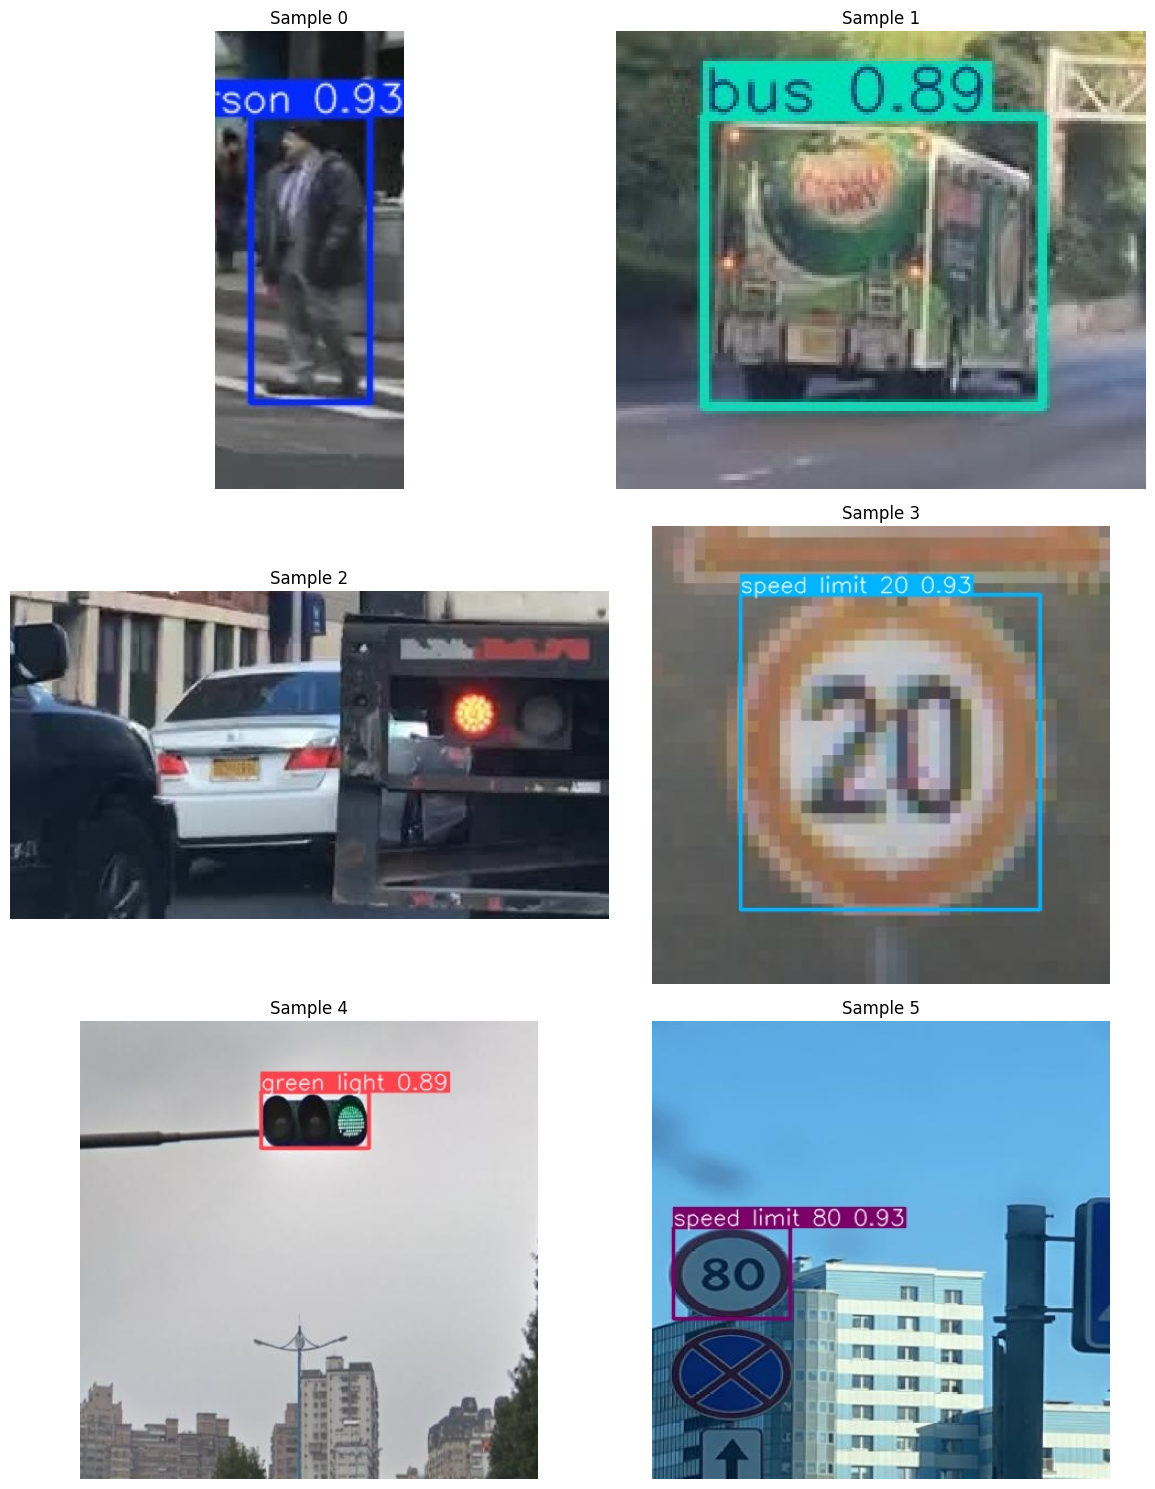

In [7]:
import glob
import math
import cv2
import matplotlib.pyplot as plt

pred_imgs = sorted(glob.glob("/kaggle/working/runs/baseline_val_preds/*"))
n = len(pred_imgs)
cols = 2
rows = math.ceil(n / cols)

fig, axes = plt.subplots(rows, cols, figsize=(12, 5 * rows))
axes = axes.flatten()

for idx, img_path in enumerate(pred_imgs):
    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    axes[idx].imshow(img)
    axes[idx].set_title(f"Sample {idx}")
    axes[idx].axis("off")

for idx in range(n, len(axes)):
    axes[idx].axis("off")

plt.tight_layout()
plt.show()